1. Percent of all search categories.

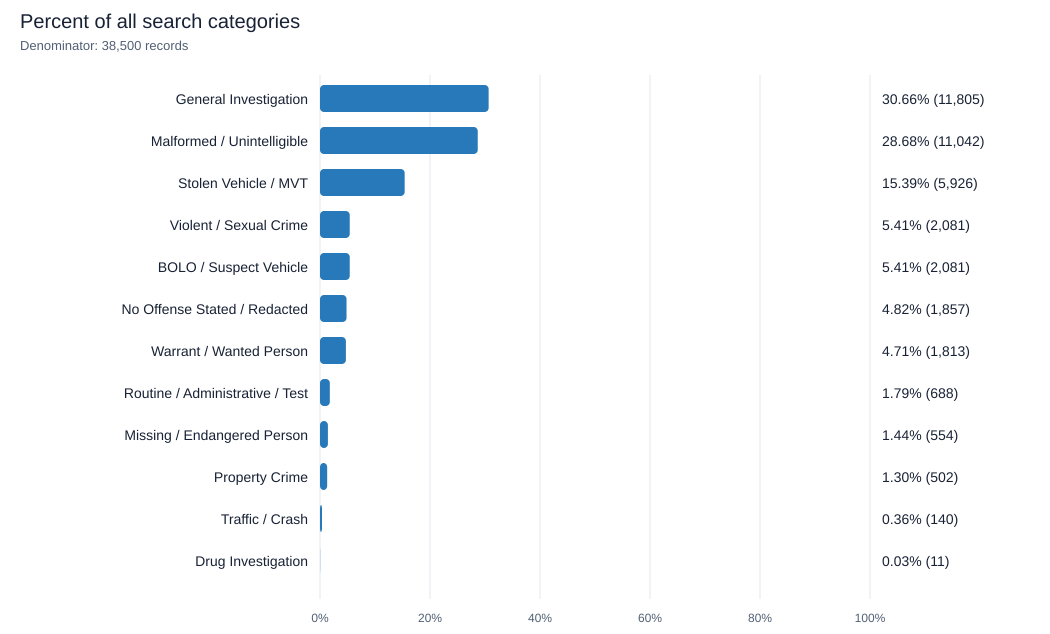

Group,Records,Percent
General Investigation,"11,805",30.66%
Malformed / Unintelligible,"11,042",28.68%
Stolen Vehicle / MVT,"5,926",15.39%
Violent / Sexual Crime,"2,081",5.41%
BOLO / Suspect Vehicle,"2,081",5.41%
No Offense Stated / Redacted,"1,857",4.82%
Warrant / Wanted Person,"1,813",4.71%
Routine / Administrative / Test,688,1.79%
Missing / Endangered Person,554,1.44%
Property Crime,502,1.30%


In [1]:
# This cell can run independently, including after a kernel restart.
import re
from collections import Counter
from html import escape
from IPython.display import HTML, display
from categorized_output.memphis_visuals import load_data, percent_chart

rows = load_data()
total = len(rows)

category_counts = Counter(row["reason_category"].strip() or "Uncategorized" for row in rows)
percent_chart(dict(category_counts.most_common()), "Percent of all search categories", total)

2. Percent of lookup and search.

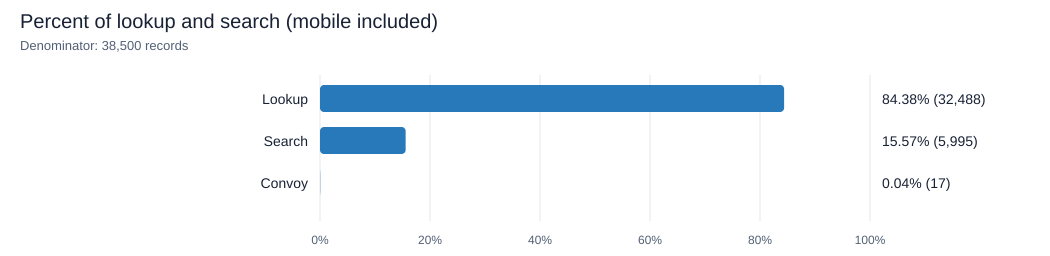

Group,Records,Percent
Lookup,"32,488",84.38%
Search,"5,995",15.57%
Convoy,17,0.04%


In [8]:
# This cell can run independently, including after a kernel restart.
import re
from collections import Counter
from html import escape
from IPython.display import HTML, display
from categorized_output.memphis_visuals import load_data, percent_chart

rows = load_data()
total = len(rows)

# Combine "lookup - Mobile" with "lookup", and "search - Mobile" with "search".
# Keep convoy and any unexpected types so all records stay in the denominator.
type_counts = Counter()
for row in rows:
    search_type = row["search_type"].strip().lower()
    base_type = re.sub(r"\s*-\s*mobile$", "", search_type)
    type_counts[base_type.title() or "Unspecified"] += 1

assert sum(type_counts.values()) == total
percent_chart(dict(type_counts.most_common()), "Percent of lookup and search (mobile included)", total)

3. Percent with blank reason.

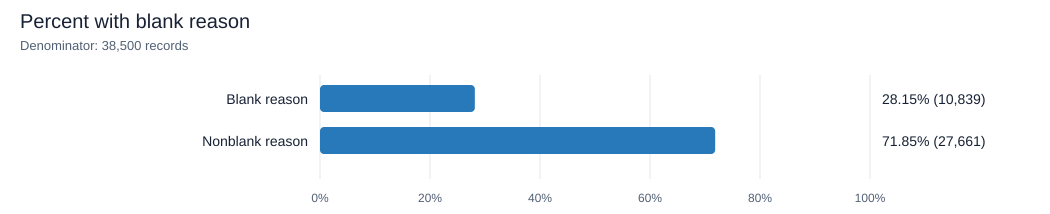

Group,Records,Percent
Blank reason,"10,839",28.15%
Nonblank reason,"27,661",71.85%


In [3]:
# This cell can run independently, including after a kernel restart.
import re
from collections import Counter
from html import escape
from IPython.display import HTML, display
from categorized_output.memphis_visuals import load_data, percent_chart

rows = load_data()
total = len(rows)

# Only an empty or whitespace-only reason counts as blank.
# Text such as UNKNOWN, NA, or a case number remains a nonblank reason.
blank_count = sum(not row["reason"].strip() for row in rows)
percent_chart({"Blank reason": blank_count, "Nonblank reason": total - blank_count},
              "Percent with blank reason", total)

4. Percent with misspelling.

In [ ]:
# This cell can run independently, including after a kernel restart.
import re
from collections import Counter
from html import escape
from IPython.display import HTML, display
from categorized_output.memphis_visuals import load_data, percent_chart

rows = load_data()
total = len(rows)

# Conservative, editable typo rules based on the reason text in this dataset.
# This is a rule-based estimate, not a comprehensive spelling assessment.
# Abbreviations (INV, MVT, ATL, LE), case numbers, and blank reasons are not typos.
# Plus signs are treated as word separators; the original CSV is never changed.
TYPO_GROUPS = {
    "INVESTIGATION": "INESTIGATION INETIGATION INVESIGATION INVESIGTION INVESTATION INVESTGAION INVESTGATION INVESTIATION INVESTIGAION INVESTIGAITON INVESTIGAQTION INVESTIGASTION INVESTIGATIN INVESTIGATON INVESTIGSTION INVESTIGTION INVESTIHATION INVESTITAGION INVETIGATION INVRSTIGATION INVSIGATION INVSTI9GATION INVSTIATION INVSTIGATION IVESTAGATION IVESTIGATIO IVESTIGATION NVESTIGATION",
    "INVESTIGATE": "INVESTGATE",
    "ROBBERY": "ROBBEERY ROBBERRY ROBERRY ROBERY",
    "CARJACKED": "CAEJACKED CARJAKED",
    "CARJACKING": "CARJCKING",
    "HOMICIDE": "HOMCIDE HOMICDE HOMOCIDE",
    "KIDNAPPING": "KDNAPPING KINAPPING",
    "MISSING": "MISSNG",
    "PERSON": "PERAON",
    "ASSAULT": "ASAULT",
    "SUSPECT": "SUSPET SUSPEVT SUSPPECT",
    "SUSPICIOUS": "SUSPICIUS",
    "STOLEN": "STOEN STOOEN",
    "VEHICLE": "VEHCILE VEHCLE VEHICE VEHICEL VEHLCE",
    "SHOPLIFTER": "SHIPLIFTER",
    "SHOOTING": "SHOTING",
    "BURGLARY": "BUGLARY",
    "WARRANT": "WARRANTT",
    "WARRANTS": "WARTRANTS",
}
TYPO_CORRECTIONS = {typo: correction
                    for correction, variants in TYPO_GROUPS.items()
                    for typo in variants.split()}
# Phrase rules capture errors that are otherwise valid words.
PHRASE_CORRECTIONS = {"HIT ADN UN": "HIT AND RUN", "STONE CAR": "STOLEN CAR"}

def normalize_reason(reason):
    return " ".join(reason.upper().replace("+", " ").split())

def spelling_matches(reason):
    text = normalize_reason(reason)
    tokens = re.findall(r"[A-Z0-9]+", text)
    matches = [f"{TYPO_CORRECTIONS[token]}"
               for token in tokens if token in TYPO_CORRECTIONS]
    if text in PHRASE_CORRECTIONS:
        matches.append(f"{PHRASE_CORRECTIONS[text]}")
    return sorted(set(matches))

# Count each record at most once, even if its reason has multiple typos.
flagged = [row for row in rows if spelling_matches(row["reason"])]
nonblank_count = sum(bool(row["reason"].strip()) for row in rows)
spelling_counts = {
    "Likely misspelling flagged": len(flagged),
    "Nonblank, no listed typo": nonblank_count - len(flagged),
    "Blank (not assessable)": total - nonblank_count,
}
percent_chart(spelling_counts, "Percent with a likely misspelling (listed rules)", total)
print(f"Flagged: {len(flagged):,} / {total:,} total records = {100 * len(flagged) / total:.2f}%")
if nonblank_count:
    print(f"Among nonblank reasons: {100 * len(flagged) / nonblank_count:.2f}%")

# Audit table: inspect exactly which reason values were counted.
flagged_reasons = Counter(row["reason"] for row in flagged)
audit_rows = [f"<tr><td>{escape(reason)}</td><td>{count:,}</td>"
              f"<td>{escape('; '.join(spelling_matches(reason)))}</td></tr>"
              for reason, count in flagged_reasons.most_common()]
display(HTML("<h4>Flagged reasons and suggested corrections</h4>"
             "<table><thead><tr><th>Reason</th><th>Records</th><th>Matched rule</th></tr></thead>"
             "<tbody>" + "".join(audit_rows) + "</tbody></table>"))


# Compare every observed typo with its corresponding correctly spelled form.
# Counts are records containing the word, including words inside longer reasons.
# Each form counts at most once per record. Phrase rules use the same exact
# normalized-reason matching as spelling_matches above.
word_record_counts = Counter()
phrase_record_counts = Counter()
for row in rows:
    text = normalize_reason(row["reason"])
    word_record_counts.update(set(re.findall(r"[A-Z0-9]+", text)))
    phrase_record_counts[text] += 1

spelling_comparison = []
for rules, counts in [(TYPO_CORRECTIONS, word_record_counts),
                      (PHRASE_CORRECTIONS, phrase_record_counts)]:
    for misspelling, correct_form in rules.items():
        typo_count = counts[misspelling]
        if not typo_count:
            continue
        correct_count = counts[correct_form]
        spelling_comparison.append({
            "misspelling": misspelling,
            "correct_form": correct_form,
            "misspelled_records": typo_count,
            "correct_records": correct_count,
            "misspelling_percent": 100 * typo_count / (typo_count + correct_count),
        })
spelling_comparison.sort(key=lambda item: (-item["misspelled_records"], item["misspelling"]))

comparison_html = []
for item in spelling_comparison:
    comparison_html.append(
        f"<tr><td>{escape(item['misspelling'])}</td>"
        f"<td>{escape(item['correct_form'])}</td>"
        f"<td>{item['misspelled_records']:,}</td>"
        f"<td>{item['correct_records']:,}</td>"
        f"<td>{item['misspelling_percent']:.2f}%</td></tr>"
    )
display(HTML(
    "<h4>Each misspelling compared with the correct form</h4>"
    "<p>Misspelling % = records with this typo ÷ "
    "(records with this typo + records with the correct form) × 100. "
    "Other typo variants are excluded from each row's denominator. "
    "The correct-form count repeats when multiple typos map to the same word. "
    "A record containing both forms contributes to both counts.</p>"
    "<table><thead><tr><th>Misspelling</th><th>Correct form</th>"
    "<th>Records with misspelling</th><th>Records with correct form</th>"
    "<th>Misspelling %</th></tr></thead><tbody>"
    + "".join(comparison_html) + "</tbody></table>"
))


: 